Debye specific heat at T = 300 K, θ_D = 300 K: 23.738 J/mol·K


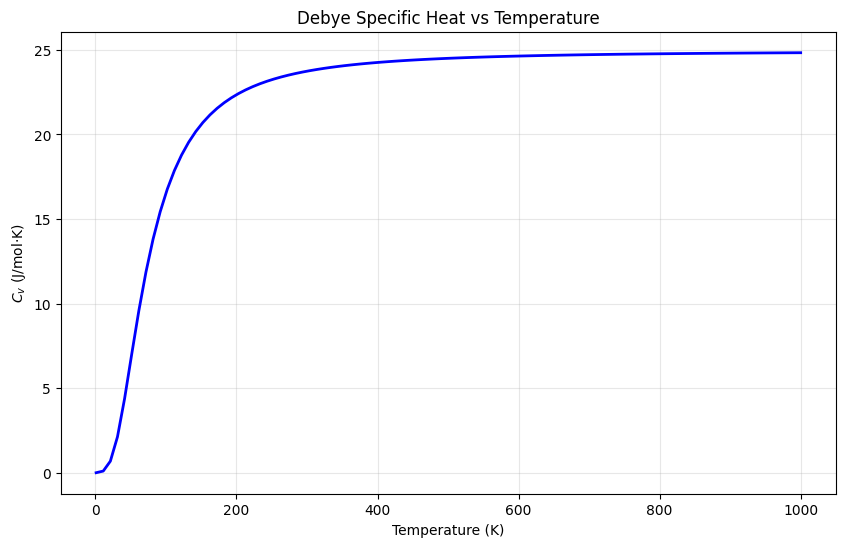

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
import sympy as sp

# Define the integral function
def debye_integrand(x):
    """Integrand for Debye specific heat: x^4 * exp(x) / (exp(x) - 1)^2"""
    return (x**4 * np.exp(x)) / (np.exp(x) - 1)**2

def C_v_debye(T, theta_D, R=8.314):
    """
    Calculate Debye specific heat

    Parameters:
    T: temperature (K)
    theta_D: Debye temperature (K)
    R: gas constant (J/mol·K)


    Returns:
    C_v: specific heat (J/mol·K)
    """
    if T == 0:
        return 0

    upper_limit = theta_D / T
    integral, error = integrate.quad(debye_integrand, 0, upper_limit)

    return 9 * R * (T / theta_D)**3 * integral

# Example calculation
T = 300  # K
theta_D = 300  # K (example for copper)
R = 8.314  # J/mol·K

C_v = C_v_debye(T, theta_D, R)
print(f"Debye specific heat at T = {T} K, θ_D = {theta_D} K: {C_v:.3f} J/mol·K")

# Temperature sweep
temperatures = np.linspace(1, 1000, 100)
C_v_values = [C_v_debye(T, theta_D, R) for T in temperatures]

plt.figure(figsize=(10, 6))
plt.plot(temperatures, C_v_values, 'b-', linewidth=2)
plt.xlabel('Temperature (K)')
plt.ylabel('$C_v$ (J/mol·K)')
plt.title('Debye Specific Heat vs Temperature')
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Symbolic computation with SymPy
def symbolic_debye_integral():
    """Attempt symbolic evaluation of the Debye integral"""
    x = sp.Symbol('x', real=True, positive=True)
    integrand = (x**4 * sp.exp(x)) / (sp.exp(x) - 1)**2

    print("Integrand:")
    sp.pprint(integrand)

    # Try to integrate symbolically
    print("\nAttempting symbolic integration...")
    try:
        integral_result = sp.integrate(integrand, x)
        print("Antiderivative:")
        sp.pprint(integral_result)
    except:
        print("Symbolic integration failed - no closed form exists")

    return integrand

# Test symbolic approach
integrand_expr = symbolic_debye_integral()

Integrand:
   4  x  
  x ⋅ℯ   
─────────
        2
⎛ x    ⎞ 
⎝ℯ  - 1⎠ 

Attempting symbolic integration...
Antiderivative:
             ⌠          
     4       ⎮    3     
    x        ⎮   x      
- ────── + 4⋅⎮ ────── dx
   x         ⎮  x       
  ℯ  - 1     ⎮ ℯ  - 1   
             ⌡          


/tmp/ipython-input-3075585588.py:9: RuntimeWarning: overflow encountered in scalar power
  return (x**4 * np.exp(x)) / (np.exp(x) - 1)**2
/tmp/ipython-input-3075585588.py:9: RuntimeWarning: overflow encountered in exp
  return (x**4 * np.exp(x)) / (np.exp(x) - 1)**2
/tmp/ipython-input-3075585588.py:9: RuntimeWarning: invalid value encountered in scalar divide
  return (x**4 * np.exp(x)) / (np.exp(x) - 1)**2
/tmp/ipython-input-3075585588.py:9: RuntimeWarning: overflow encountered in scalar multiply
  return (x**4 * np.exp(x)) / (np.exp(x) - 1)**2
/tmp/ipython-input-3075585588.py:27: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  integral, error = integrate.quad(debye_integrand, 0, upper_limit)
/tmp/ipython-input-3075585588.py:27: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised

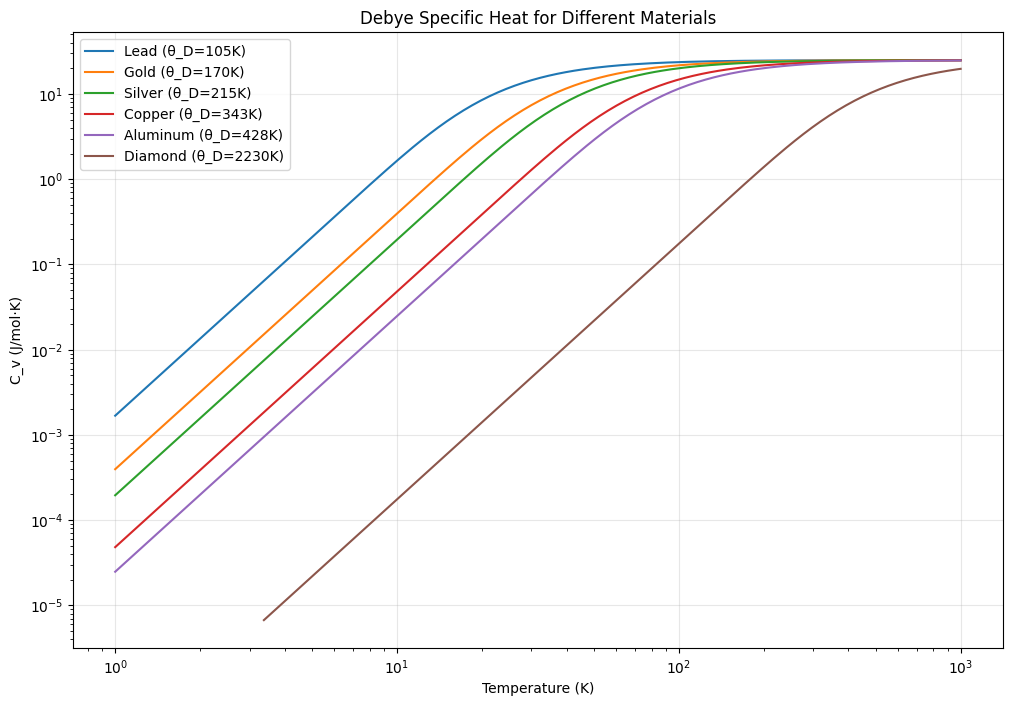

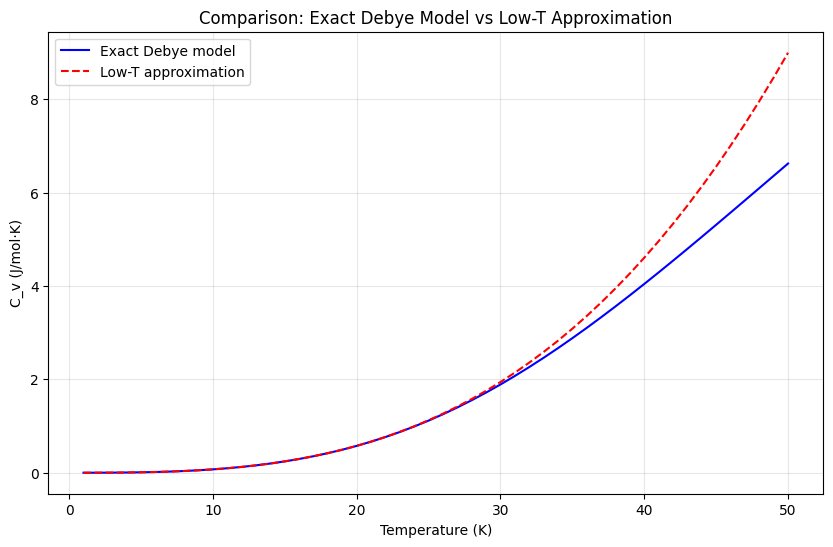

In [ ]:
# Comprehensive analysis with different Debye temperatures
def analyze_debye_model():
    """Compare different materials and temperature regimes"""

    # Different materials with their Debye temperatures
    materials = {
        'Lead': 105,
        'Gold': 170,
        'Silver': 215,
        'Copper': 343,
        'Aluminum': 428,
        'Diamond': 2230
    }

    T_range = np.logspace(0, 3, 200)  # 1 to 1000 K

    plt.figure(figsize=(12, 8))

    for material, theta_D in materials.items():
        C_v_vals = [C_v_debye(T, theta_D) for T in T_range]
        plt.loglog(T_range, C_v_vals, label=f'{material} (θ_D={theta_D}K)')

    plt.xlabel('Temperature (K)')
    plt.ylabel('C_v (J/mol·K)')
    plt.title('Debye Specific Heat for Different Materials')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

# Run the analysis
analyze_debye_model()

# Low temperature limit verification (T << θ_D)
def low_temp_approximation(T, theta_D, R=8.314):
    """Low temperature approximation: C_v ≈ (12π⁴/5)R(T/θ_D)³"""
    return (12 * np.pi**4 / 5) * R * (T / theta_D)**3

# Compare exact vs low-T approximation
T_low = np.linspace(1, 50, 50)
theta_D_test = 300

C_v_exact = [C_v_debye(T, theta_D_test) for T in T_low]
C_v_approx = [low_temp_approximation(T, theta_D_test) for T in T_low]

plt.figure(figsize=(10, 6))
plt.plot(T_low, C_v_exact, 'b-', label='Exact Debye model')
plt.plot(T_low, C_v_approx, 'r--', label='Low-T approximation')
plt.xlabel('Temperature (K)')
plt.ylabel('C_v (J/mol·K)')
plt.title('Comparison: Exact Debye Model vs Low-T Approximation')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from scipy import special

def debye_integral_series(u):
    """
    Alternative implementation using series expansion for better numerical stability
    """
    if u > 100:  # For very large u, use asymptotic expansion
        return 4 * np.pi**4 / 5 - 12 * np.exp(-u) * (u**3 + 3*u**2 + 6*u + 6)

    # For normal range, use numerical integration
    result, error = integrate.quad(lambda x: x**4 * np.exp(x) / (np.exp(x) - 1)**2, 0, u)
    return result

def C_v_debye_precise(T, theta_D, R=8.314):
    """More precise implementation of Debye specific heat"""
    if T == 0:

        return 0

    u = theta_D / T
    integral = debye_integral_series(u)

    return 9 * R * (T / theta_D)**3 * integral

# Test the precise version
print("High-precision calculation:")
for T in [10, 100, 300, 1000]:
    C_v_precise = C_v_debye_precise(T, theta_D)
    print(f"T = {T:4d} K: C_v = {C_v_precise:.4f} J/mol·K")

High-precision calculation:
T =   10 K: C_v = 0.0720 J/mol·K
T =  100 K: C_v = 16.5305 J/mol·K
T =  300 K: C_v = 23.7381 J/mol·K
T = 1000 K: C_v = 24.8301 J/mol·K
